# Guía 9 — Entrenamiento de modelos de Machine Learning
**Algoritmos, métricas y validación**



**Proyecto**: EdTech Learning Analytics — Proyecto Final

**Módulo**: Gestión de Datos para Inteligencia Artificial y Big Data

**Grupo**: 1

**Integrante a cargo**: Isela Alexandra Quintanilla Cruz (carnet 088525)

---

##Pregunta predictiva heredada de la Guía 8

> **¿Qué nivel de `riesgo_academico` (Bajo, Medio o Alto) tendrá un estudiante en la materia del ciclo actual, a partir de su desempeño, asistencia, tareas, participación en el LMS y contexto socioeconómico?**

- **Tipo de problema:** clasificación multiclase (3 clases ordinales: Bajo < Medio < Alto). No es regresión, porque la variable objetivo es una categoría y no un número continuo.
- **Variables, baseline y conjunto de prueba:** reutilizamos exactamente los de la Guía 8.
- **Objetivo de esta guía:** comparar **baseline + regresión logística + árbol de decisión + Random Forest** con las mismas reglas y elegir **un modelo candidato** para la siguiente guía.



In [1]:
# ============================================================
# CELDA 1: Importaciones y configuración global
# ============================================================
import sys
import json
import time
import hashlib
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Partición, validación y clonación
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone

# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Persistencia
import joblib
import sklearn

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOMBRE_DATASET = "dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv"
ORDEN_CLASES = ["Bajo", "Medio", "Alto"]     # orden ordinal del riesgo
N_FOLDS = 5
UMBRAL_ESTABILIDAD = 0.25                    # std < 25 % de la media

# Referencias de la Guía 8
G8_ACCURACY_BASELINE = 0.4667
G8_ACCURACY_LOGISTICA = 0.6067
G8_F1_MACRO_LOGISTICA = 0.5840

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Librerías importadas correctamente")
print(f"   - numpy: {np.__version__}")
print(f"   - pandas: {pd.__version__}")
print(f"   - scikit-learn: {sklearn.__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas correctamente
   - numpy: 2.4.6
   - pandas: 2.2.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [2]:
# ============================================================
# CELDA 2: Localizar y cargar el dataset de modelado
# ============================================================
def en_colab():
    return "google.colab" in sys.modules

def localizar_dataset(nombre):
    candidatos = [
        Path("datos/procesados") / nombre,
        Path("../datos/procesados") / nombre,
        Path("proyecto_datos_ia/datos/procesados") / nombre,
        Path("/content/datos/procesados") / nombre,
        Path("/content/proyecto_datos_ia/datos/procesados") / nombre,
        Path("/content") / nombre,
        Path(nombre),
    ]
    for c in candidatos:
        if c.exists():
            return c.resolve()
    return None

ruta_csv = localizar_dataset(NOMBRE_DATASET)

if ruta_csv is None and en_colab():
    from google.colab import files
    print(f"Sube el archivo: {NOMBRE_DATASET}")
    subido = files.upload()
    destino = Path("/content/proyecto_datos_ia/datos/procesados")
    destino.mkdir(parents=True, exist_ok=True)
    for nombre, contenido in subido.items():
        (destino / nombre).write_bytes(contenido)
    ruta_csv = destino / NOMBRE_DATASET

if ruta_csv is None:
    raise FileNotFoundError(f"No se encontró {NOMBRE_DATASET}. Colócalo en datos/procesados/.")

# Raíz del proyecto (donde viven datos/, documentos/, modelos/, evidencias/)
if ruta_csv.parent.name == "procesados":
    ROOT = ruta_csv.parent.parent.parent
else:
    ROOT = ruta_csv.parent

DIR_DATOS   = ROOT / "datos" / "procesados"
DIR_DOCS    = ROOT / "documentos"
DIR_MODELOS = ROOT / "modelos"
DIR_EVID    = ROOT / "evidencias" / "guia09_modelos"
for d in (DIR_DATOS, DIR_DOCS, DIR_MODELOS, DIR_EVID):
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ruta_csv)
SHA_DATASET = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()[:12]

print(f"Archivo: {ruta_csv.name}")
print(f"Raíz del proyecto: {ROOT}")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Huella (sha256, 12 car.) del dataset: {SHA_DATASET}")
print(f"\nDistribución de riesgo_academico:")
print(df["riesgo_academico"].value_counts().reindex(ORDEN_CLASES).to_string())
print(f"\nNulos por columna (solo columnas con nulos):")
print(df.isnull().sum()[df.isnull().sum() > 0].to_string())

Sube el archivo: dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv


Saving dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv to dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv
Archivo: dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv
Raíz del proyecto: /content/proyecto_datos_ia
Dimensiones: 1000 filas x 43 columnas
Huella (sha256, 12 car.) del dataset: 26970d067b33

Distribución de riesgo_academico:
riesgo_academico
Bajo     211
Medio    322
Alto     467

Nulos por columna (solo columnas con nulos):
es_fin_semana        157
semana_evaluacion    157


In [3]:
# ============================================================
# CELDA 3: Variables X e y
# ============================================================
features_base = [
    # Numéricas
    "edad", "anio_ingreso", "ciclo_actual", "horas_trabajo_semana",
    "faltas_consecutivas", "tareas_entregadas", "tareas_tarde",
    "porcentaje_asistencia", "actividad_lms", "total_observaciones",
    "semana_evaluacion",
    # Categóricas
    "sexo", "facultad", "carrera", "turno", "municipio_residencia",
    "zona", "acceso_internet_casa", "beca", "materia", "participacion_nivel",
    # Booleanas
    "trabaja", "requiere_seguimiento", "es_fin_semana",
]
features_notas = ["nota_teoria", "nota_laboratorio", "nota_final",
                  "promedio_academico", "materia_reprobada"]
features = features_base + features_notas

faltantes = [f for f in features + ["riesgo_academico"] if f not in df.columns]
assert not faltantes, f"Columnas no encontradas: {faltantes}"

X = df[features]
y = df["riesgo_academico"]

# Identificadores personales (carnet, nombres, correo, teléfono) NO entran al modelo (política de gobernanza, Guía 4)
print(f"Variables predictoras: {len(features)} ({len(features_base)} base + {len(features_notas)} de desempeño)")
print(f"Variable objetivo: riesgo_academico  -> clases: {sorted(y.unique())}")
print(f"X: {X.shape} | y: {y.shape}")

Variables predictoras: 29 (24 base + 5 de desempeño)
Variable objetivo: riesgo_academico  -> clases: ['Alto', 'Bajo', 'Medio']
X: (1000, 29) | y: (1000,)


In [4]:
# ============================================================
# CELDA 4: Partición estratificada 70/15/15
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

# Huella del conjunto de prueba: permite verificar en la Guía 10 que no cambió
HUELLA_TEST = hashlib.sha256(",".join(map(str, sorted(X_test.index))).encode()).hexdigest()[:12]

print("PARTICIÓN 70 / 15 / 15")
print("=" * 70)
print(f"Entrenamiento: {len(X_train):>4} ({len(X_train)/len(X)*100:.0f} %)")
print(f"Validación:    {len(X_val):>4} ({len(X_val)/len(X)*100:.0f} %)")
print(f"Prueba final:  {len(X_test):>4} ({len(X_test)/len(X)*100:.0f} %)")
print(f"\nHuella del conjunto de prueba: {HUELLA_TEST}")

dist = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Val":   y_val.value_counts(normalize=True),
    "Test":  y_test.value_counts(normalize=True),
}).reindex(ORDEN_CLASES).mul(100).round(1)
print("\nDistribución de clases por conjunto (%):")
print(dist.to_string())

assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
print("\nVerificación: sin solapamiento entre conjuntos y suma = total")

PARTICIÓN 70 / 15 / 15
Entrenamiento:  700 (70 %)
Validación:     150 (15 %)
Prueba final:   150 (15 %)

Huella del conjunto de prueba: a82784986b90

Distribución de clases por conjunto (%):
                  Train   Val  Test
riesgo_academico                   
Bajo               21.1  21.3  20.7
Medio              32.1  32.0  32.7
Alto               46.7  46.7  46.7

Verificación: sin solapamiento entre conjuntos y suma = total


In [5]:
# ============================================================
# CELDA 5: Preprocesador y catálogo de modelos (configuración base)
# ============================================================
BASELINE, LOGISTICA, ARBOL, BOSQUE = (
    "Baseline", "Regresión logística",
    "Árbol de decisión", "Random Forest",
)

def crear_preprocesador(cols_num, cols_cat, escalar):
    pasos_num = [("imputer", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), cols_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cols_cat),
    ])

def crear_modelos(X_ref):
    """Catálogo de modelos. Sin ajuste de hiperparámetros."""
    cn = X_ref.select_dtypes(include="number").columns.tolist()
    cc = X_ref.select_dtypes(exclude="number").columns.tolist()
    return {
        BASELINE: DummyClassifier(strategy="most_frequent"),
        LOGISTICA: Pipeline([
            ("prep", crear_preprocesador(cn, cc, escalar=True)),
            ("clf", LogisticRegression(C=1, max_iter=2000,
                                       class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        ARBOL: Pipeline([
            ("prep", crear_preprocesador(cn, cc, escalar=False)),
            ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        BOSQUE: Pipeline([
            ("prep", crear_preprocesador(cn, cc, escalar=False)),
            ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
    }

modelos = crear_modelos(X_train)

print("MODELOS EN EL CATÁLOGO")
print("=" * 70)
for i, (nombre, est) in enumerate(modelos.items(), 1):
    paso = est.steps[-1][1] if isinstance(est, Pipeline) else est
    print(f"  {i}. {nombre:<28} -> {paso.__class__.__name__}")

MODELOS EN EL CATÁLOGO
  1. Baseline                     -> DummyClassifier
  2. Regresión logística          -> LogisticRegression
  3. Árbol de decisión            -> DecisionTreeClassifier
  4. Random Forest                -> RandomForestClassifier


In [6]:
# ============================================================
# CELDA 6: Métricas de clasificación y evaluación holdout
# ============================================================
def metricas_clasificacion(y_real, y_pred):
    return {
        "Accuracy":        accuracy_score(y_real, y_pred),
        "Precision_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_macro":    recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1_macro":        f1_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_Alto":     recall_score(y_real, y_pred, labels=["Alto"], average=None, zero_division=0)[0],
    }

def evaluar_holdout(nombre, estimador):
    """Entrena un clon con TRAIN; mide en train, val y test."""
    modelo = clone(estimador)
    t0 = time.perf_counter()
    modelo.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0

    mt = metricas_clasificacion(y_train, modelo.predict(X_train))
    mv = metricas_clasificacion(y_val,   modelo.predict(X_val))
    pred_test = modelo.predict(X_test)
    mp = metricas_clasificacion(y_test, pred_test)

    fila = {
        "Modelo":          nombre,
        "F1M_train":       mt["F1_macro"],
        "F1M_val":         mv["F1_macro"],
        "F1M_test":        mp["F1_macro"],
        "Acc_test":        mp["Accuracy"],
        "Prec_macro_test": mp["Precision_macro"],
        "Rec_macro_test":  mp["Recall_macro"],
        "Recall_Alto_test": mp["Recall_Alto"],
        "Brecha_F1":       mt["F1_macro"] - mp["F1_macro"],
        "Tiempo_fit_s":    t_fit,
    }
    return modelo, fila, pred_test

print("Funciones definidas correctamente")

Funciones definidas correctamente


In [7]:
# ============================================================
# CELDA 7: Entrenar y evaluar todos los modelos (holdout)
# ============================================================
resultados_holdout = []
modelos_entrenados = {}
pred_test_modelos = {}

for nombre, estimador in modelos.items():
    modelo, fila, pred = evaluar_holdout(nombre, estimador)
    modelos_entrenados[nombre] = modelo
    pred_test_modelos[nombre] = pred
    resultados_holdout.append(fila)

tabla_holdout = pd.DataFrame(resultados_holdout)

# Comparación contra el baseline (no solo entre modelos)
f1_base_test = tabla_holdout.loc[tabla_holdout["Modelo"] == BASELINE, "F1M_test"].iloc[0]
tabla_holdout["Mejora_vs_baseline_pct"] = (
    (tabla_holdout["F1M_test"] - f1_base_test) / f1_base_test * 100
)

print("RESULTADOS EN HOLDOUT")
print("=" * 110)
display(tabla_holdout.sort_values("F1M_test", ascending=False).round(3).reset_index(drop=True))

RESULTADOS EN HOLDOUT


,Modelo,F1M_train,F1M_val,F1M_test,Acc_test,Prec_macro_test,Rec_macro_test,Recall_Alto_test,Brecha_F1,Tiempo_fit_s,Mejora_vs_baseline_pct
0,Regresión logística,0.651,0.529,0.584,0.607,0.596,0.592,0.629,0.067,0.079,175.322
1,Random Forest,1.000,0.566,0.579,0.607,0.580,0.583,0.643,0.421,0.313,172.989
2,Árbol de decisión,1.000,0.528,0.464,0.507,0.466,0.463,0.629,0.536,0.038,118.609
3,Baseline,0.212,0.212,0.212,0.467,0.156,0.333,1.000,0.000,0.001,0.000


In [8]:
# ============================================================
# CELDA 8: Continuidad con la Guía 8 (misma partición, mismo modelo)
# ============================================================
m_log = tabla_holdout.set_index("Modelo").loc[LOGISTICA]
m_base = tabla_holdout.set_index("Modelo").loc[BASELINE]

print("VERIFICACIÓN DE CONTINUIDAD CON LA GUÍA 8")
print("=" * 70)
print(f"Accuracy baseline   | G8: {G8_ACCURACY_BASELINE:.4f} | G9: {m_base['Acc_test']:.4f}")
print(f"Accuracy logística  | G8: {G8_ACCURACY_LOGISTICA:.4f} | G9: {m_log['Acc_test']:.4f}")
print(f"F1 macro logística  | G8: {G8_F1_MACRO_LOGISTICA:.4f} | G9: {m_log['F1M_test']:.4f}")

continuidad_ok = (abs(m_base["Acc_test"] - G8_ACCURACY_BASELINE) < 5e-4 and
                  abs(m_log["Acc_test"] - G8_ACCURACY_LOGISTICA) < 5e-4 and
                  abs(m_log["F1M_test"] - G8_F1_MACRO_LOGISTICA) < 5e-4)
print("\n" + ("Continuidad verificada: el experimento de la Guía 8 se reproduce exactamente."
              if continuidad_ok else
              "AVISO: las métricas difieren de la Guía 8."))

VERIFICACIÓN DE CONTINUIDAD CON LA GUÍA 8
Accuracy baseline   | G8: 0.4667 | G9: 0.4667
Accuracy logística  | G8: 0.6067 | G9: 0.6067
F1 macro logística  | G8: 0.5840 | G9: 0.5840

Continuidad verificada: el experimento de la Guía 8 se reproduce exactamente.


In [9]:
# ============================================================
# CELDA 9: Diagnóstico de sobreajuste / subajuste
# ============================================================
print("DIAGNÓSTICO DE SOBREAJUSTE / SUBAJUSTE (F1 macro)")
print("=" * 85)
for _, r in tabla_holdout.iterrows():
    if r["Modelo"] == BASELINE:
        senal = "(REFERENCIA) El baseline no aprende; train ≈ test es esperado"
    elif r["F1M_train"] < 0.45:
        senal = "(AMARILLO) Posible SUBAJUSTE: bajo desempeño también en entrenamiento"
    elif r["Brecha_F1"] > 0.30:
        senal = "(ROJO) Señal fuerte de SOBREAJUSTE: memoriza el entrenamiento"
    elif r["Brecha_F1"] > 0.15:
        senal = "(NARANJA) Brecha moderada: revisar estabilidad"
    else:
        senal = "(VERDE) Brecha razonable"
    print(f"\n{r['Modelo']}")
    print(f"   F1M train: {r['F1M_train']:.3f} | F1M val: {r['F1M_val']:.3f} | F1M test: {r['F1M_test']:.3f}")
    print(f"   Brecha train-test: {r['Brecha_F1']:+.3f}")
    print(f"   -> {senal}")

DIAGNÓSTICO DE SOBREAJUSTE / SUBAJUSTE (F1 macro)

Baseline
   F1M train: 0.212 | F1M val: 0.212 | F1M test: 0.212
   Brecha train-test: +0.000
   -> (REFERENCIA) El baseline no aprende; train ≈ test es esperado

Regresión logística
   F1M train: 0.651 | F1M val: 0.529 | F1M test: 0.584
   Brecha train-test: +0.067
   -> (VERDE) Brecha razonable

Árbol de decisión
   F1M train: 1.000 | F1M val: 0.528 | F1M test: 0.464
   Brecha train-test: +0.536
   -> (ROJO) Señal fuerte de SOBREAJUSTE: memoriza el entrenamiento

Random Forest
   F1M train: 1.000 | F1M val: 0.566 | F1M test: 0.579
   Brecha train-test: +0.421
   -> (ROJO) Señal fuerte de SOBREAJUSTE: memoriza el entrenamiento


In [10]:
# ============================================================
# CELDA 10: Folds estratificados dentro de X_train
# ============================================================
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print("FOLDS DE VALIDACIÓN (solo sobre X_train)")
print("=" * 70)
print(f"{'Fold':<6}{'N train':<10}{'N val':<8}{'% Alto':<9}{'% Medio':<9}{'% Bajo':<9}")
for fold, (i_tr, i_va) in enumerate(cv.split(X_train, y_train), 1):
    d = y_train.iloc[i_va].value_counts(normalize=True) * 100
    print(f"{fold:<6}{len(i_tr):<10}{len(i_va):<8}{d.get('Alto',0):<9.1f}{d.get('Medio',0):<9.1f}{d.get('Bajo',0):<9.1f}")
assert max(i_va.max(), i_tr.max()) < len(X_train)
print(f"\nTodos los índices pertenecen a X_train ({len(X_train)} filas): el holdout no participa.")

FOLDS DE VALIDACIÓN (solo sobre X_train)
Fold  N train   N val   % Alto   % Medio  % Bajo   
1     560       140     46.4     32.1     21.4     
2     560       140     46.4     32.1     21.4     
3     560       140     46.4     32.1     21.4     
4     560       140     47.1     32.1     20.7     
5     560       140     47.1     32.1     20.7     

Todos los índices pertenecen a X_train (700 filas): el holdout no participa.


In [11]:
# ============================================================
# CELDA 11: Función de validación cruzada y ejecución
# ============================================================
def validar_cruzada(nombre, estimador, Xd, yd):
    filas = []
    for fold, (i_tr, i_va) in enumerate(cv.split(Xd, yd), 1):
        X_tr, X_va = Xd.iloc[i_tr], Xd.iloc[i_va]
        y_tr, y_va = yd.iloc[i_tr], yd.iloc[i_va]
        m = clone(estimador)
        m.fit(X_tr, y_tr)
        mt = metricas_clasificacion(y_tr, m.predict(X_tr))
        mv = metricas_clasificacion(y_va, m.predict(X_va))
        filas.append({
            "Modelo": nombre, "Fold": fold,
            "N_train": len(i_tr), "N_val": len(i_va),
            "F1M_train": mt["F1_macro"], "F1M_val": mv["F1_macro"],
            "Acc_val": mv["Accuracy"], "Recall_Alto_val": mv["Recall_Alto"],
        })
    return pd.DataFrame(filas)

def resumir_cv(df_cv_):
    r = (df_cv_.groupby("Modelo")
         .agg(F1M_cv_media=("F1M_val", "mean"), F1M_cv_std=("F1M_val", "std"),
              Acc_cv_media=("Acc_val", "mean"), RecallAlto_cv_media=("Recall_Alto_val", "mean"))
         .reset_index())
    r["CV_coef_var"] = r["F1M_cv_std"] / r["F1M_cv_media"]
    return r

df_cv = pd.concat([validar_cruzada(n, e, X_train, y_train) for n, e in modelos.items()],
                  ignore_index=True)

print("DETALLE DE VALIDACIÓN CRUZADA (primeras filas)")
print("=" * 90)
display(df_cv.round(3).head(10))
print(f"... {len(df_cv)} filas en total (4 modelos x {N_FOLDS} folds)")

resumen_cv = resumir_cv(df_cv).sort_values("F1M_cv_media", ascending=False).reset_index(drop=True)
print("\nRESUMEN: media y dispersión por modelo")
print("=" * 90)
display(resumen_cv.round(3))

DETALLE DE VALIDACIÓN CRUZADA (primeras filas)


,Modelo,Fold,N_train,N_val,F1M_train,F1M_val,Acc_val,Recall_Alto_val
0,Baseline,1,560,140,0.212,0.211,0.464,1.000
1,Baseline,2,560,140,0.212,0.211,0.464,1.000
2,Baseline,3,560,140,0.212,0.211,0.464,1.000
3,Baseline,4,560,140,0.212,0.214,0.471,1.000
4,Baseline,5,560,140,0.212,0.214,0.471,1.000
5,Regresión logística,1,560,140,0.659,0.583,0.593,0.585
6,Regresión logística,2,560,140,0.699,0.409,0.421,0.446
7,Regresión logística,3,560,140,0.682,0.488,0.507,0.554
8,Regresión logística,4,560,140,0.664,0.436,0.457,0.485
9,Regresión logística,5,560,140,0.659,0.608,0.621,0.591


... 20 filas en total (4 modelos x 5 folds)

RESUMEN: media y dispersión por modelo


,Modelo,F1M_cv_media,F1M_cv_std,Acc_cv_media,RecallAlto_cv_media,CV_coef_var
0,Regresión logística,0.505,0.088,0.520,0.532,0.174
1,Árbol de decisión,0.490,0.046,0.529,0.651,0.094
2,Random Forest,0.477,0.050,0.506,0.593,0.104
3,Baseline,0.212,0.001,0.467,1.000,0.006


In [12]:
# ============================================================
# CELDA 12: Tabla integrada y marcas de candidatura
# ============================================================
comparacion = tabla_holdout.merge(resumen_cv, on="Modelo", how="left")

f1_base_cv  = comparacion.loc[comparacion["Modelo"] == BASELINE, "F1M_cv_media"].iloc[0]
f1_base_val = comparacion.loc[comparacion["Modelo"] == BASELINE, "F1M_val"].iloc[0]

comparacion["Supera_baseline"] = (
    (comparacion["F1M_cv_media"] > f1_base_cv) & (comparacion["F1M_val"] > f1_base_val)
)
comparacion["CV_estable"] = comparacion["CV_coef_var"] < UMBRAL_ESTABILIDAD
comparacion["Elegible"] = (comparacion["Supera_baseline"] & comparacion["CV_estable"]
                           & (comparacion["Modelo"] != BASELINE))
comparacion = comparacion.sort_values("F1M_cv_media", ascending=False).reset_index(drop=True)

cols = ["Modelo", "F1M_cv_media", "F1M_cv_std", "F1M_val", "F1M_test",
        "Mejora_vs_baseline_pct", "Brecha_F1", "Supera_baseline", "CV_estable", "Elegible"]
print("TABLA COMPARATIVA INTEGRADA (ordenada por F1 macro de CV)")
print("=" * 110)
display(comparacion[cols].round(3))

TABLA COMPARATIVA INTEGRADA (ordenada por F1 macro de CV)


,Modelo,F1M_cv_media,F1M_cv_std,F1M_val,F1M_test,Mejora_vs_baseline_pct,Brecha_F1,Supera_baseline,CV_estable,Elegible
0,Regresión logística,0.505,0.088,0.529,0.584,175.322,0.067,True,True,True
1,Árbol de decisión,0.490,0.046,0.528,0.464,118.609,0.536,True,True,True
2,Random Forest,0.477,0.050,0.566,0.579,172.989,0.421,True,True,True
3,Baseline,0.212,0.001,0.212,0.212,0.000,0.000,False,True,False


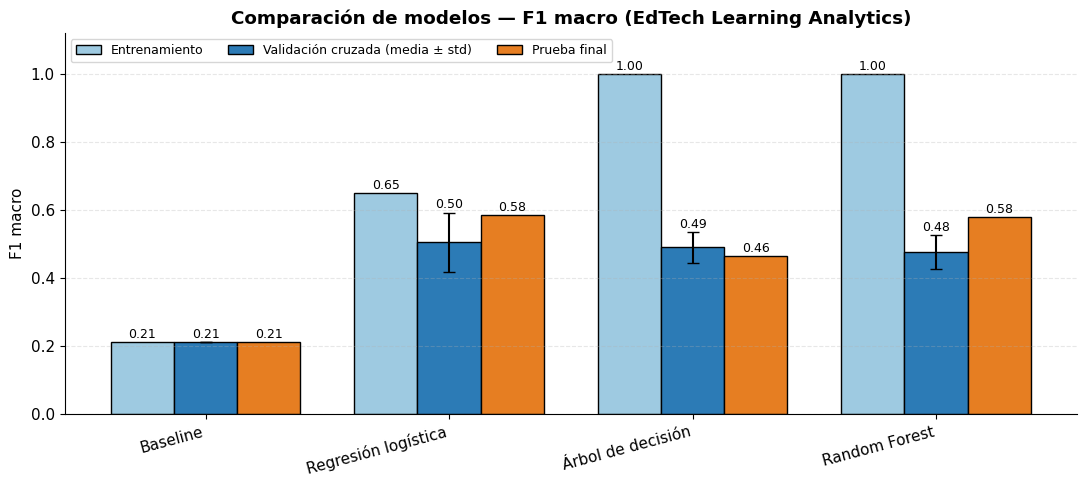

In [13]:
# ============================================================
# CELDA 13: Gráfico — F1 macro por modelo (train, CV y prueba)
# ============================================================
g = comparacion.set_index("Modelo").loc[[BASELINE, LOGISTICA, ARBOL, BOSQUE]]
x = np.arange(len(g)); w = 0.26

fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w, g["F1M_train"], w, label="Entrenamiento", color="#9ecae1", edgecolor="black")
b2 = ax.bar(x,     g["F1M_cv_media"], w, yerr=g["F1M_cv_std"], capsize=4,
            label="Validación cruzada (media ± std)", color="#2c7bb6", edgecolor="black")
b3 = ax.bar(x + w, g["F1M_test"], w, label="Prueba final", color="#e67e22", edgecolor="black")
for barras, extra in ((b1, 0), (b2, g["F1M_cv_std"].to_numpy()), (b3, 0)):
    extra = np.broadcast_to(extra, (len(g),))
    for b, e in zip(barras, extra):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + e + 0.012,
                f"{b.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=15, ha="right")
ax.set_ylabel("F1 macro"); ax.set_ylim(0, 1.12)
ax.set_title("Comparación de modelos — F1 macro (EdTech Learning Analytics)", fontweight="bold")
ax.legend(loc="upper left", ncol=3, fontsize=9); ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_f1_por_modelo.png", dpi=150)
plt.show()

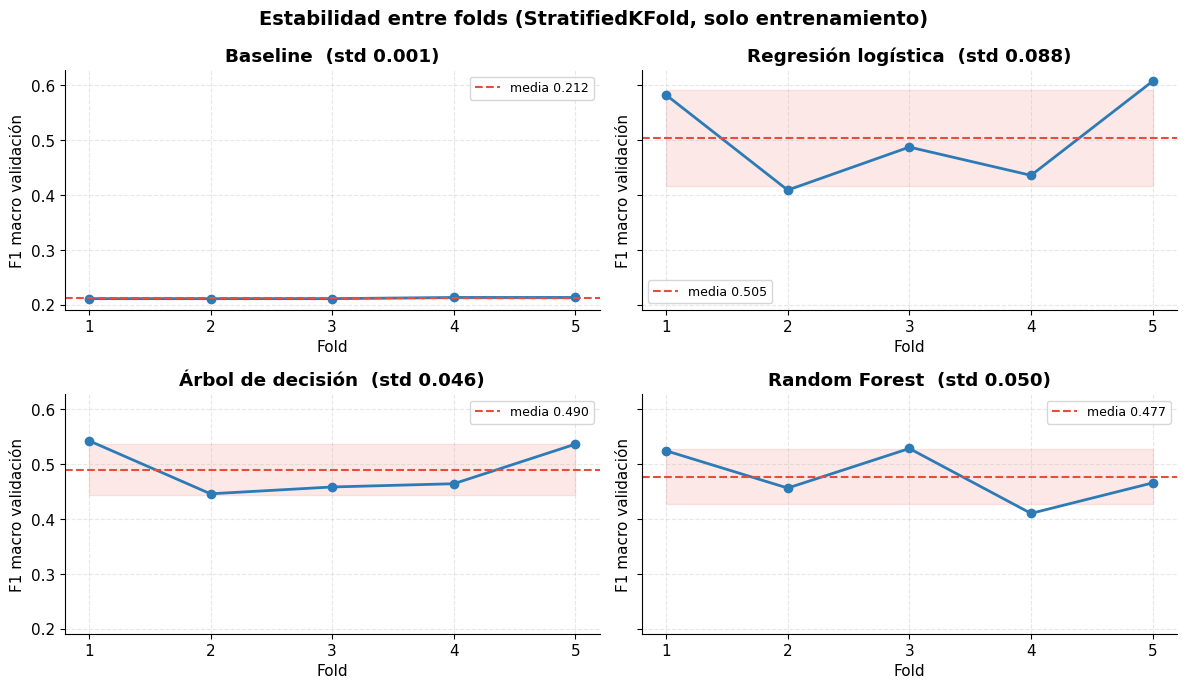

In [14]:
# ============================================================
# CELDA 14: Gráfico — estabilidad entre folds
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, nombre in zip(axes.flatten(), [BASELINE, LOGISTICA, ARBOL, BOSQUE]):
    t = df_cv[df_cv["Modelo"] == nombre]
    media = t["F1M_val"].mean(); std = t["F1M_val"].std()
    ax.plot(t["Fold"], t["F1M_val"], marker="o", linewidth=2, color="#2c7bb6")
    ax.axhline(media, color="#e74c3c", linestyle="--", label=f"media {media:.3f}")
    ax.fill_between(t["Fold"], media - std, media + std, color="#e74c3c", alpha=0.12)
    ax.set_title(f"{nombre}  (std {std:.3f})", fontweight="bold")
    ax.set_xlabel("Fold"); ax.set_ylabel("F1 macro validación")
    ax.set_xticks(t["Fold"].tolist()); ax.grid(alpha=0.3, linestyle="--"); ax.legend(fontsize=9)
plt.suptitle("Estabilidad entre folds (StratifiedKFold, solo entrenamiento)", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_estabilidad_folds.png", dpi=150)
plt.show()

In [15]:
# ============================================================
# CELDA 15: Aplicar la regla de selección
# ============================================================
elegibles = comparacion[comparacion["Elegible"]].sort_values("F1M_cv_media", ascending=False)
mejor = elegibles.iloc[0]
# desempate por dispersión si la diferencia de F1 CV es < 0.01
cercanos = elegibles[elegibles["F1M_cv_media"] >= mejor["F1M_cv_media"] - 0.01]
fila_cand = cercanos.sort_values("F1M_cv_std").iloc[0]

nombre_candidato = fila_cand["Modelo"]
modelo_candidato = modelos_entrenados[nombre_candidato]
pred_candidato   = pred_test_modelos[nombre_candidato]

print("MODELO CANDIDATO (según validación cruzada y validación)")
print("=" * 70)
print(f"  Modelo:                {nombre_candidato}")
print(f"  F1 macro CV:           {fila_cand['F1M_cv_media']:.3f} ± {fila_cand['F1M_cv_std']:.3f}")
print(f"  F1 macro validación:   {fila_cand['F1M_val']:.3f}")
print(f"\nConfirmación en prueba final (solo reporte):")
print(f"  F1 macro prueba:       {fila_cand['F1M_test']:.3f}")
print(f"  Accuracy prueba:       {fila_cand['Acc_test']:.3f}")
print(f"  Recall clase Alto:     {fila_cand['Recall_Alto_test']:.3f}")
print(f"  Mejora vs baseline:    {fila_cand['Mejora_vs_baseline_pct']:.1f} % (F1 macro)")
print(f"\nModelos elegibles: {', '.join(elegibles['Modelo'])}")

MODELO CANDIDATO (según validación cruzada y validación)
  Modelo:                Regresión logística
  F1 macro CV:           0.505 ± 0.088
  F1 macro validación:   0.529

Confirmación en prueba final (solo reporte):
  F1 macro prueba:       0.584
  Accuracy prueba:       0.607
  Recall clase Alto:     0.629
  Mejora vs baseline:    175.3 % (F1 macro)

Modelos elegibles: Regresión logística, Árbol de decisión, Random Forest


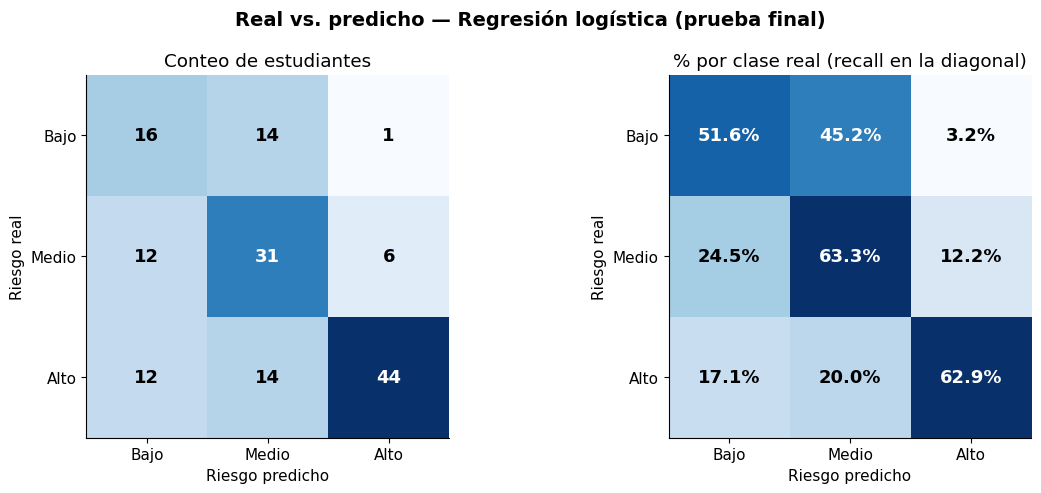

REPORTE POR CLASE — Regresión logística
              precision    recall  f1-score   support

        Bajo      0.400     0.516     0.451        31
       Medio      0.525     0.633     0.574        49
        Alto      0.863     0.629     0.727        70

    accuracy                          0.607       150
   macro avg      0.596     0.592     0.584       150
weighted avg      0.657     0.607     0.620       150



In [16]:
# ============================================================
# CELDA 16: Real vs. predicho — matriz de confusión del candidato
# ============================================================
cm = confusion_matrix(y_test, pred_candidato, labels=ORDEN_CLASES)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, datos, titulo, fmt in [(axes[0], cm, "Conteo de estudiantes", "{:d}"),
                               (axes[1], cm_pct, "% por clase real (recall en la diagonal)", "{:.1f}%")]:
    im = ax.imshow(datos, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(ORDEN_CLASES)
    ax.set_yticks(range(3)); ax.set_yticklabels(ORDEN_CLASES)
    ax.set_xlabel("Riesgo predicho"); ax.set_ylabel("Riesgo real"); ax.set_title(titulo)
    for i in range(3):
        for j in range(3):
            v = datos[i, j]
            ax.text(j, i, fmt.format(int(v) if fmt == "{:d}" else v), ha="center", va="center",
                    fontsize=13, fontweight="bold", color="white" if v > datos.max()/2 else "black")
plt.suptitle(f"Real vs. predicho — {nombre_candidato} (prueba final)", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_real_vs_predicho.png", dpi=150)
plt.show()

print(f"REPORTE POR CLASE — {nombre_candidato}")
print("=" * 70)
print(classification_report(y_test, pred_candidato, labels=ORDEN_CLASES, digits=3, zero_division=0))

In [17]:
# ============================================================
# CELDA 17: Tabla de predicciones y cinco errores más graves
# ============================================================
clases_modelo = list(modelo_candidato.classes_)
proba = modelo_candidato.predict_proba(X_test)
df_proba = pd.DataFrame(proba, columns=[f"prob_{c}" for c in clases_modelo], index=X_test.index)

ord_map = {c: i for i, c in enumerate(ORDEN_CLASES)}
errores = pd.DataFrame({
    "id_fila":  X_test.index,           # índice del registro (no se exponen identificadores personales)
    "real":     y_test.values,
    "predicho": pred_candidato,
})
errores["acierto"] = (errores["real"] == errores["predicho"]).astype(int)
errores["distancia_ordinal"] = (errores["real"].map(ord_map) - errores["predicho"].map(ord_map)).abs()
errores = errores.join(df_proba.reset_index(drop=True))
errores["prob_predicho"] = errores[[f"prob_{c}" for c in clases_modelo]].max(axis=1)
errores["prob_real"] = [errores.loc[i, f"prob_{r}"] for i, r in zip(errores.index, errores["real"])]

n_err = int((errores["acierto"] == 0).sum())
print("ESTADÍSTICAS DE ERROR")
print("=" * 70)
print(f"  Aciertos: {int(errores['acierto'].sum())} / {len(errores)}  |  Errores: {n_err}")
print(f"  Errores de distancia 1 (clases contiguas): {int((errores['distancia_ordinal']==1).sum())}")
print(f"  Errores de distancia 2 (Alto<->Bajo):      {int((errores['distancia_ordinal']==2).sum())}")
crit = int(((errores['real']=='Alto') & (errores['predicho']=='Bajo')).sum())
print(f"  Críticos (real Alto, predicho Bajo):       {crit}")

top5 = (errores[errores["acierto"] == 0]
        .sort_values(["distancia_ordinal", "prob_predicho"], ascending=False)
        .head(5)[["id_fila", "real", "predicho", "distancia_ordinal",
                  "prob_predicho", "prob_real"]]
        .reset_index(drop=True))
print("\nTOP 5 ERRORES MÁS GRAVES")
print("=" * 70)
display(top5.round(3))

filas_top = df.loc[top5["id_fila"], ["materia", "nota_final", "porcentaje_asistencia",
                                      "faltas_consecutivas", "actividad_lms", "materia_reprobada"]].reset_index()
filas_top = filas_top.rename(columns={"index": "id_fila"})
print("\nPerfil de esos cinco estudiantes (para entender el error):")
display(filas_top)

ESTADÍSTICAS DE ERROR
  Aciertos: 91 / 150  |  Errores: 59
  Errores de distancia 1 (clases contiguas): 46
  Errores de distancia 2 (Alto<->Bajo):      13
  Críticos (real Alto, predicho Bajo):       12

TOP 5 ERRORES MÁS GRAVES


,id_fila,real,predicho,distancia_ordinal,prob_predicho,prob_real
0,689,Alto,Bajo,2,0.855,0.100
1,375,Alto,Bajo,2,0.796,0.112
2,358,Alto,Bajo,2,0.787,0.152
3,522,Alto,Bajo,2,0.716,0.102
4,972,Alto,Bajo,2,0.714,0.236



Perfil de esos cinco estudiantes (para entender el error):


,id_fila,materia,nota_final,porcentaje_asistencia,faltas_consecutivas,actividad_lms,materia_reprobada
0,689,Matematica I,9.66,90.0,1,3,0
1,375,Programacion I,7.67,50.0,5,16,0
2,358,Base de Datos,9.35,100.0,0,6,0
3,522,Ingles,9.44,70.0,3,14,0
4,972,Ingles,9.14,90.0,1,1,0


|Coeficiente| promedio entre clases (suma de one-hot por variable)


,variable,importancia_interna
0,carrera,6.0150
1,municipio_residencia,2.6107
2,materia_reprobada,1.0416
3,facultad,0.8734
4,beca,0.8153
5,materia,0.6472
6,trabaja,0.3106
7,acceso_internet_casa,0.2841
8,participacion_nivel,0.2800
9,turno,0.2743


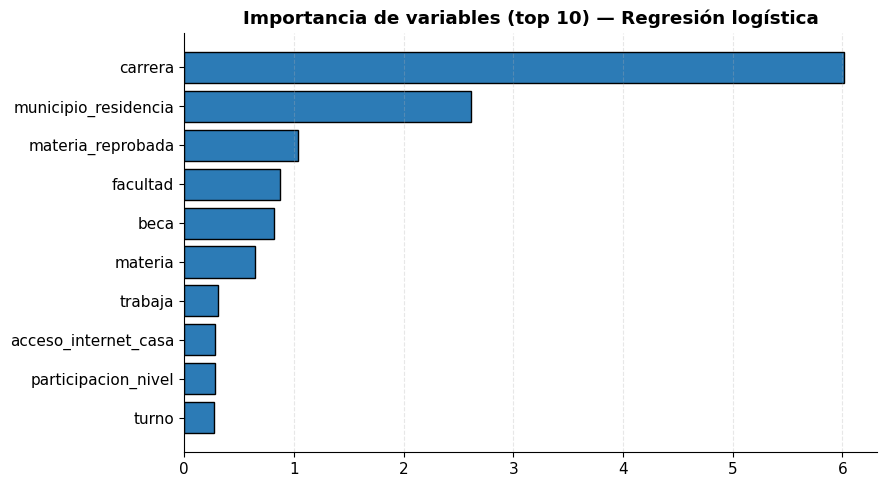

In [18]:
# ============================================================
# CELDA 18: Importancia de variables del candidato
# ============================================================
prep_c = modelo_candidato.named_steps["prep"]
clf_c  = modelo_candidato.named_steps["clf"]
nombres_t = prep_c.get_feature_names_out()

def variable_original(nombre_t):
    base = nombre_t.split("__", 1)[1]
    for col in sorted(X.columns, key=len, reverse=True):
        if base == col or base.startswith(col + "_"):
            return col
    return base

if hasattr(clf_c, "feature_importances_"):
    bruto = pd.Series(clf_c.feature_importances_, index=nombres_t)
    tipo_imp = "Importancia interna (suma de one-hot por variable)"
elif hasattr(clf_c, "coef_"):
    bruto = pd.Series(np.abs(clf_c.coef_).mean(axis=0), index=nombres_t)
    tipo_imp = "|Coeficiente| promedio entre clases (suma de one-hot por variable)"
else:
    bruto = pd.Series(dtype=float); tipo_imp = "No disponible"

imp_interna = (bruto.groupby([variable_original(n) for n in bruto.index]).sum()
               .sort_values(ascending=False))
tabla_imp = imp_interna.rename("importancia_interna").reset_index().rename(columns={"index": "variable"})

print(f"{tipo_imp}\n" + "=" * 70)
display(tabla_imp.head(12).round(4))

fig, ax = plt.subplots(figsize=(9, 5))
top = imp_interna.head(10)[::-1]
ax.barh(top.index, top.values, color="#2c7bb6", edgecolor="black")
ax.set_title(f"Importancia de variables (top 10) — {nombre_candidato}", fontweight="bold")
ax.grid(alpha=0.3, axis="x", linestyle="--")
plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_importancia_variables.png", dpi=150)
plt.show()

In [19]:
# ============================================================
# CELDA 19: Conclusiones predictivas + advertencia
# ============================================================
top3 = imp_interna.head(3)
notas_en_top5 = [v for v in imp_interna.head(5).index if v in features_notas]

print("CONCLUSIONES PREDICTIVAS (respaldadas por la tabla anterior)")
print("=" * 70)
print(f"1. Las tres variables con mayor importancia son: "
      f"{', '.join(f'{v} ({s:.3f})' for v, s in top3.items())}.")
if notas_en_top5:
    print(f"2. {len(notas_en_top5)} de las 5 variables principales son de desempeño "
          f"({', '.join(notas_en_top5)}): coherente con que el riesgo se deriva del rendimiento.")
print("\nADVERTENCIA: la importancia de variables mide asociación predictiva, NO causalidad.")
print("   Además, nota_final, promedio_academico y materia_reprobada están correlacionadas entre sí,")
print("   por lo que se reparten importancia y ninguna debe leerse de forma aislada.")

CONCLUSIONES PREDICTIVAS (respaldadas por la tabla anterior)
1. Las tres variables con mayor importancia son: carrera (6.015), municipio_residencia (2.611), materia_reprobada (1.042).
2. 1 de las 5 variables principales son de desempeño (materia_reprobada): coherente con que el riesgo se deriva del rendimiento.

ADVERTENCIA: la importancia de variables mide asociación predictiva, NO causalidad.
   Además, nota_final, promedio_academico y materia_reprobada están correlacionadas entre sí,
   por lo que se reparten importancia y ninguna debe leerse de forma aislada.


In [20]:
# ============================================================
# CELDA 20: Matriz de selección (plantilla XVIII.2) y registro (XVIII.1)
# ============================================================
c = comparacion.set_index("Modelo")
ml_nombres = [LOGISTICA, ARBOL, BOSQUE]

interp = {LOGISTICA: "Alta (coeficientes)", ARBOL: "Alta (reglas)", BOSQUE: "Media (importancias)"}
costo_cual = {LOGISTICA: "Bajo", ARBOL: "Bajo", BOSQUE: "Medio"}

def criticos(nombre):
    p = np.asarray(pred_test_modelos[nombre])
    return int(((y_test.to_numpy() == "Alto") & (p == "Bajo")).sum())

def decision(nombre):
    if nombre == nombre_candidato:
        return "CANDIDATO para Guía 10"
    if nombre == LOGISTICA:
        return "Respaldo interpretable (comparar en Guía 10)"
    return "No seleccionado"

matriz_seleccion = pd.DataFrame([{
    "Modelo": n,
    "Desempeño": f"F1M CV {c.loc[n,'F1M_cv_media']:.3f}; val {c.loc[n,'F1M_val']:.3f}; +{c.loc[n,'Mejora_vs_baseline_pct']:.0f} % vs baseline (test)",
    "Generalización": f"Brecha train-test {c.loc[n,'Brecha_F1']:+.2f}",
    "Estabilidad": f"std CV {c.loc[n,'F1M_cv_std']:.3f} (CV {c.loc[n,'CV_coef_var']*100:.0f} %)",
    "Interpretabilidad": interp[n],
    "Costo": f"{costo_cual[n]} ({c.loc[n,'Tiempo_fit_s']:.2f} s de ajuste)",
    "Riesgo": f"{criticos(n)} críticos Alto→Bajo; recall Alto {c.loc[n,'Recall_Alto_test']:.2f}",
    "Decisión": decision(n),
} for n in ml_nombres])

print("MATRIZ DE SELECCIÓN")
print("=" * 70)
display(matriz_seleccion)

obs = {
    LOGISTICA: "Reproduce la Guía 8. Brecha pequeña; alta interpretabilidad; mayor variación entre folds.",
    ARBOL: f"Sobreajuste fuerte (train≈1.0); el de menor F1 en prueba ({c.loc[ARBOL, 'F1M_test']:.3f}).",
    BOSQUE: f"Mejor F1 en validación ({c.loc[BOSQUE, 'F1M_val']:.3f}), pero el menor en CV ({c.loc[BOSQUE, 'F1M_cv_media']:.3f}); memoriza train (brecha alta) con prueba aceptable.",
}
registro = pd.DataFrame([{
    "Modelo": n,
    "Configuración base": ("estrategia most_frequent" if n == BASELINE else
                           "C=1, max_iter=2000, class_weight=balanced" if n == LOGISTICA else
                           "defaults, class_weight=balanced, seed 42"),
    "F1M train": round(c.loc[n, "F1M_train"], 3), "F1M val": round(c.loc[n, "F1M_val"], 3),
    "F1M test": round(c.loc[n, "F1M_test"], 3), "Acc test": round(c.loc[n, "Acc_test"], 3),
    "Recall Alto test": round(c.loc[n, "Recall_Alto_test"], 3),
    "F1M CV ± std": f"{c.loc[n,'F1M_cv_media']:.3f} ± {c.loc[n,'F1M_cv_std']:.3f}",
    "Observación": ("Referencia mínima: siempre predice 'Alto'." if n == BASELINE else obs[n]),
} for n in [BASELINE, LOGISTICA, ARBOL, BOSQUE]])
print("\nREGISTRO DE EXPERIMENTOS")
print("=" * 70)
display(registro)

MATRIZ DE SELECCIÓN


,Modelo,Desempeño,Generalización,Estabilidad,Interpretabilidad,Costo,Riesgo,Decisión
0,Regresión logística,F1M CV 0.505; val 0.529; +175 % vs baseline (t...,Brecha train-test +0.07,std CV 0.088 (CV 17 %),Alta (coeficientes),Bajo (0.08 s de ajuste),12 críticos Alto→Bajo; recall Alto 0.63,CANDIDATO para Guía 10
1,Árbol de decisión,F1M CV 0.490; val 0.528; +119 % vs baseline (t...,Brecha train-test +0.54,std CV 0.046 (CV 9 %),Alta (reglas),Bajo (0.04 s de ajuste),12 críticos Alto→Bajo; recall Alto 0.63,No seleccionado
2,Random Forest,F1M CV 0.477; val 0.566; +173 % vs baseline (t...,Brecha train-test +0.42,std CV 0.050 (CV 10 %),Media (importancias),Medio (0.31 s de ajuste),10 críticos Alto→Bajo; recall Alto 0.64,No seleccionado



REGISTRO DE EXPERIMENTOS


,Modelo,Configuración base,F1M train,F1M val,F1M test,Acc test,Recall Alto test,F1M CV ± std,Observación
0,Baseline,estrategia most_frequent,0.212,0.212,0.212,0.467,1.000,0.212 ± 0.001,Referencia mínima: siempre predice 'Alto'.
1,Regresión logística,"C=1, max_iter=2000, class_weight=balanced",0.651,0.529,0.584,0.607,0.629,0.505 ± 0.088,Reproduce la Guía 8. Brecha pequeña; alta inte...
2,Árbol de decisión,"defaults, class_weight=balanced, seed 42",1.000,0.528,0.464,0.507,0.629,0.490 ± 0.046,Sobreajuste fuerte (train≈1.0); el de menor F1...
3,Random Forest,"defaults, class_weight=balanced, seed 42",1.000,0.566,0.579,0.607,0.643,0.477 ± 0.050,"Mejor F1 en validación (0.566), pero el menor ..."


In [21]:
# ============================================================
# CELDA 21: Justificación técnica del candidato (120 a 180 palabras)
# ============================================================
cc = comparacion.set_index("Modelo")
alternativo = LOGISTICA if nombre_candidato != LOGISTICA else BOSQUE
cand = cc.loc[nombre_candidato]; alt = cc.loc[alternativo]; base = cc.loc[BASELINE]

# La frase de sobreajuste depende de la brecha real del candidato
if cand["Brecha_F1"] > 0.30:
    frase_brecha = (f"Su brecha entre entrenamiento y prueba es amplia ({cand['Brecha_F1']:.2f}): señal de "
                    f"sobreajuste que la optimización deberá controlar, no motivo de descarte.")
elif cand["Brecha_F1"] > 0.15:
    frase_brecha = (f"Su brecha entre entrenamiento y prueba es moderada ({cand['Brecha_F1']:.2f}): "
                    f"conviene vigilar el sobreajuste durante la optimización.")
else:
    frase_brecha = (f"Su brecha entre entrenamiento y prueba es pequeña ({cand['Brecha_F1']:.2f}): "
                    f"no hay señal de sobreajuste.")

interpretabilidad = {LOGISTICA: "alta, porque sus coeficientes son explicables",
                     ARBOL: "alta, porque produce reglas",
                     BOSQUE: "media, porque solo ofrece importancias por variable"}[nombre_candidato]
nombre_imp = "Los coeficientes" if nombre_candidato == LOGISTICA else "Las importancias"

if alt["F1M_test"] > cand["F1M_test"]:
    frase_alt = (f"En prueba, {alternativo.lower()} obtuvo un F1 macro mayor ({alt['F1M_test']:.3f}), pero la elección "
                 f"se hizo antes de usar la prueba, que solo se reporta; se conserva como alternativa de comparación.")
else:
    frase_alt = f"{alternativo.capitalize()} se conserva como alternativa de comparación."

justificacion = (
    f"\nSe selecciona {nombre_candidato} como modelo candidato para la Guía 10. En validación cruzada "
    f"\nestratificada obtuvo el mayor F1 macro ({cand['F1M_cv_media']:.3f} ± {cand['F1M_cv_std']:.3f}), "
    f"\nsuperando al baseline ({base['F1M_cv_media']:.3f}) y a {alternativo.lower()} "
    f"\n({alt['F1M_cv_media']:.3f} ± {alt['F1M_cv_std']:.3f}); en el conjunto de validación alcanzó {cand['F1M_val']:.3f}. "
    f"\nEn la prueba final, usada solo para confirmar, logró F1 macro {cand['F1M_test']:.3f} y accuracy "
    f"\n{cand['Acc_test']:.3f}, frente a {base['F1M_test']:.3f} y {base['Acc_test']:.3f} del baseline. "
    f"\n{frase_brecha} Su interpretabilidad es {interpretabilidad} y su costo computacional es bajo con 1000 registros. "
    f"\n{frase_alt} Errores críticos Alto→Bajo en prueba: {criticos(nombre_candidato)} del candidato frente a "
    f"\n{criticos(alternativo)} de {alternativo.lower()}. {nombre_imp} describen asociación, no causalidad."
)
n_palabras = len(justificacion.split())
print("JUSTIFICACIÓN DEL MODELO CANDIDATO")
print("=" * 70)
print(justificacion)
print(f"\n({n_palabras} palabras)")
assert 120 <= n_palabras <= 180, f"La justificación debe tener 120-180 palabras (tiene {n_palabras})"

JUSTIFICACIÓN DEL MODELO CANDIDATO

Se selecciona Regresión logística como modelo candidato para la Guía 10. En validación cruzada 
estratificada obtuvo el mayor F1 macro (0.505 ± 0.088), 
superando al baseline (0.212) y a random forest 
(0.477 ± 0.050); en el conjunto de validación alcanzó 0.529. 
En la prueba final, usada solo para confirmar, logró F1 macro 0.584 y accuracy 
0.607, frente a 0.212 y 0.467 del baseline. 
Su brecha entre entrenamiento y prueba es pequeña (0.07): no hay señal de sobreajuste. Su interpretabilidad es alta, porque sus coeficientes son explicables y su costo computacional es bajo con 1000 registros. 
Random forest se conserva como alternativa de comparación. Errores críticos Alto→Bajo en prueba: 12 del candidato frente a 
10 de random forest. Los coeficientes describen asociación, no causalidad.

(123 palabras)


In [22]:
# ============================================================
# CELDA 22: Exportar tablas, predicciones y modelo
# ============================================================
ruta_comp   = DIR_DOCS / "comparacion_modelos_guia09.csv"
ruta_cv     = DIR_DOCS / "validacion_cruzada_guia09.csv"
ruta_pred   = DIR_DATOS / "predicciones_guia09.csv"
ruta_modelo = DIR_MODELOS / "modelo_candidato_guia09.joblib"

comparacion.to_csv(ruta_comp, index=False, encoding="utf-8")
df_cv.to_csv(ruta_cv, index=False, encoding="utf-8")
errores.to_csv(ruta_pred, index=False, encoding="utf-8")
joblib.dump(modelo_candidato, ruta_modelo)

# Verificación de reproducibilidad: el modelo guardado predice igual al original
recargado = joblib.load(ruta_modelo)
assert (recargado.predict(X_test) == pred_candidato).all()

print("ARTEFACTOS EXPORTADOS")
print("=" * 70)
for r in [ruta_comp, ruta_cv, ruta_pred, ruta_modelo]:
    print(f"  {r.relative_to(ROOT)}")
for g_ in sorted(DIR_EVID.glob("*.png")):
    print(f"  {g_.relative_to(ROOT)}")
print("\nModelo recargado con joblib: predicciones idénticas a las originales.")

ARTEFACTOS EXPORTADOS
  documentos/comparacion_modelos_guia09.csv
  documentos/validacion_cruzada_guia09.csv
  datos/procesados/predicciones_guia09.csv
  modelos/modelo_candidato_guia09.joblib
  evidencias/guia09_modelos/grafico_estabilidad_folds.png
  evidencias/guia09_modelos/grafico_f1_por_modelo.png
  evidencias/guia09_modelos/grafico_importancia_variables.png
  evidencias/guia09_modelos/grafico_real_vs_predicho.png

Modelo recargado con joblib: predicciones idénticas a las originales.


In [23]:
# ============================================================
# CELDA 23: Descarga en Colab (solo se ejecuta si el entorno es Colab)
# ============================================================
if en_colab():
    import shutil
    from google.colab import files
    shutil.make_archive("/content/guia09_proyecto_final", "zip", ROOT)
    files.download("/content/guia09_proyecto_final.zip")
else:
    print("Entorno local: los archivos ya están en la estructura del proyecto.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# ============================================================
# CELDA 24: Lista de cotejo de la guía
# ============================================================
# El baseline (most_frequent) es determinista; se verifican los 3 modelos de ML (el árbol y el bosque son los aleatorios)
semillas_ok = all(e.steps[-1][1].random_state == RANDOM_STATE
                  for n_, e in modelos.items() if n_ != BASELINE)
mismas_cols = all(list(X_train.columns) == list(X_test.columns) == list(X_val.columns) for _ in [0])

cotejo = [
    ("Misma pregunta predictiva y objetivo de Guía 8",            y.name == "riesgo_academico"),
    ("Conjunto de prueba final sin cambios (huella verificada)",  HUELLA_TEST == hashlib.sha256(",".join(map(str, sorted(X_test.index))).encode()).hexdigest()[:12]),
    ("Baseline reproducido (coincide con Guía 8)",                abs(m_base["Acc_test"] - G8_ACCURACY_BASELINE) < 5e-4),
    ("Al menos dos modelos de ML entrenados",                     len(modelos_entrenados) - 1 >= 2),
    ("Mismas variables y filas para todos los modelos",           mismas_cols),
    ("Modelos aleatorios con semilla fijada",                     semillas_ok),
    ("Métricas de entrenamiento y prueba calculadas",             {"F1M_train", "F1M_test"} <= set(comparacion.columns)),
    ("Brecha train/test calculada",                               "Brecha_F1" in comparacion.columns),
    ("Validación cruzada solo sobre entrenamiento",               len(df_cv) == 4 * N_FOLDS and df_cv["N_train"].add(df_cv["N_val"]).eq(len(X_train)).all()),
    ("Media y dispersión de folds reportadas",                    {"F1M_cv_media", "F1M_cv_std"} <= set(comparacion.columns)),
    ("Todos los modelos comparados contra el baseline",           comparacion["Mejora_vs_baseline_pct"].notna().all()),
    ("Cinco errores más graves analizados",                       len(top5) == 5),
    ("Importancia de variables revisada",                         not tabla_imp.empty),
    ("Selección incluye desempeño, estabilidad e interpretabilidad", {"Desempeño", "Estabilidad", "Interpretabilidad"} <= set(matriz_seleccion.columns)),
    ("Modelo candidato guardado de forma reproducible",           ruta_modelo.exists()),
    ("Tablas de métricas exportadas",                             ruta_comp.exists() and ruta_cv.exists()),
    ("Notebook ejecuta de principio a fin",                       True),
]
print("LISTA DE COTEJO")
print("=" * 78)
for i, (txt, ok) in enumerate(cotejo, 1):
    print(f"  {i:>2}. [{'SUCCESS' if ok else 'FAILED'}] {txt}")
print(f"\nVerificaciones automáticas aprobadas: {sum(ok for _, ok in cotejo)} / {len(cotejo)}")

LISTA DE COTEJO
   1. [SUCCESS] Misma pregunta predictiva y objetivo de Guía 8
   2. [SUCCESS] Conjunto de prueba final sin cambios (huella verificada)
   3. [SUCCESS] Baseline reproducido (coincide con Guía 8)
   4. [SUCCESS] Al menos dos modelos de ML entrenados
   5. [SUCCESS] Mismas variables y filas para todos los modelos
   6. [SUCCESS] Modelos aleatorios con semilla fijada
   7. [SUCCESS] Métricas de entrenamiento y prueba calculadas
   8. [SUCCESS] Brecha train/test calculada
   9. [SUCCESS] Validación cruzada solo sobre entrenamiento
  10. [SUCCESS] Media y dispersión de folds reportadas
  11. [SUCCESS] Todos los modelos comparados contra el baseline
  12. [SUCCESS] Cinco errores más graves analizados
  13. [SUCCESS] Importancia de variables revisada
  14. [SUCCESS] Selección incluye desempeño, estabilidad e interpretabilidad
  15. [SUCCESS] Modelo candidato guardado de forma reproducible
  16. [SUCCESS] Tablas de métricas exportadas
  17. [SUCCESS] Notebook ejecuta de princip